In [22]:
import pulp as plp 
import matplotlib.pyplot as plt 
from itertools import product

In [23]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [24]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]
print(f"Dimensões do palete: {palete_comprimento} x {palete_largura}")
print(f"Dimensões da caixa: {caixa_comprimento} x {caixa_largura}")

Dimensões do palete: 8 x 6
Dimensões da caixa: 3 x 2


In [25]:
dimensoes_palete = [palete_comprimento, palete_largura]
L, W = sorted (dimensoes_palete, reverse=True)
print(f"Dimensões classificadas do palete: {L} X {W}")

Dimensões classificadas do palete: 8 X 6


In [26]:
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted (dimensoes_caixa, reverse=True)
print(f"Dimensões classificadas da caixa: {l_um} x {w_um}")


Dimensões classificadas da caixa: 3 x 2


In [27]:
l_dois, w_dois = dimensoes_caixa[::-1]
print (f"Dimensões classificadas da caixa em pé: {l_dois} x {w_dois}")


Dimensões classificadas da caixa em pé: 2 x 3


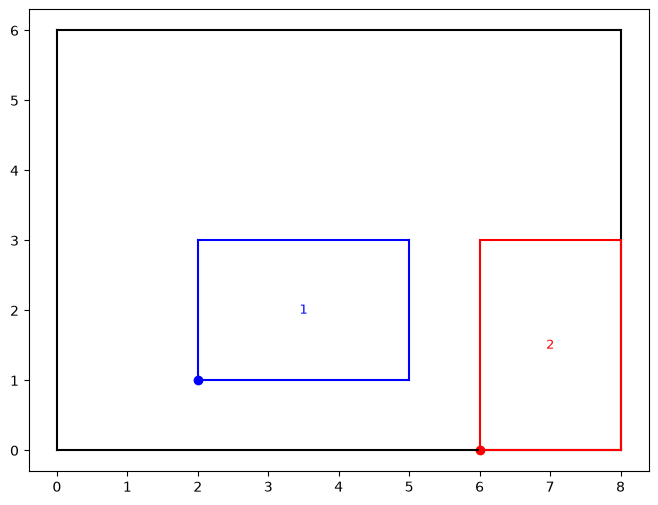

In [28]:
def plotar_caixa(bottom_left: list,
                 l: int,
                 w: int,
                 color:str,
                 label:str):
    x0, y0 =bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0+l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0+ w], color=color)
    plt.plot([x0, x0+l], [y0+ w, y0+ w], color=color)
    plt.plot([x0+ l, x0+ l], [y0, y0 + w], color=color)
    plt.text(x=x0+ l/2, y=y0 + w/2, s=label, color=color, fontsize=9, ha="center", va="center")
def plotar_palete (L: int, W:int):
    plt.figure(figsize=(8,6))
    plt.plot([0,L], [0, 0], "k-")
    plt.plot([0,0], [0, W], "k-")
    plt.plot([0,L], [W, W], "k-")
    plt.plot([L,L], [0, W], "k-")
plotar_palete(L, W)
plotar_caixa(bottom_left=[2,1], l=3, w=2, color="blue", label="1")
plotar_caixa(bottom_left=[6,0], l=2, w=3, color="red", label="2")


In [29]:
f_um = lambda n_um, l_um, n_dois, l_dois: \
    n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois: \
    n_um * w_um + n_dois * w_dois 

In [30]:
print(f_um(n_um = 1, l_um =3, n_dois = 2, l_dois = 2)) #p <= L - w_um

7


In [31]:
print(f_dois(n_um = 2, w_um =2, n_dois = 0, w_dois = 3)) #p <= W - w_um

4


0 0 0
1 0 3
2 0 6
3 0 9
4 0 12
5 0 15
6 0 18
7 0 21
0 1 2
1 1 5
2 1 8
3 1 11
4 1 14
5 1 17
6 1 20
7 1 23
0 2 4
1 2 7
2 2 10
3 2 13
4 2 16
5 2 19
6 2 22
7 2 25
0 3 6
1 3 9
2 3 12
3 3 15
4 3 18
5 3 21
6 3 24
7 3 27
0 4 8
1 4 11
2 4 14
3 4 17
4 4 20
5 4 23
6 4 26
7 4 29
0 5 10
1 5 13
2 5 16
3 5 19
4 5 22
5 5 25
6 5 28
7 5 31
0 6 12
1 6 15
2 6 18
3 6 21
4 6 24
5 6 27
6 6 30
7 6 33
0 7 14
1 7 17
2 7 20
3 7 23
4 7 26
5 7 29
6 7 32
7 7 35


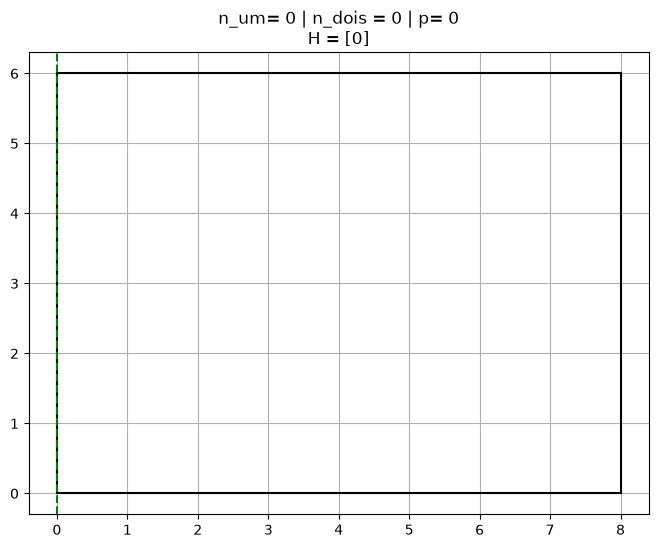

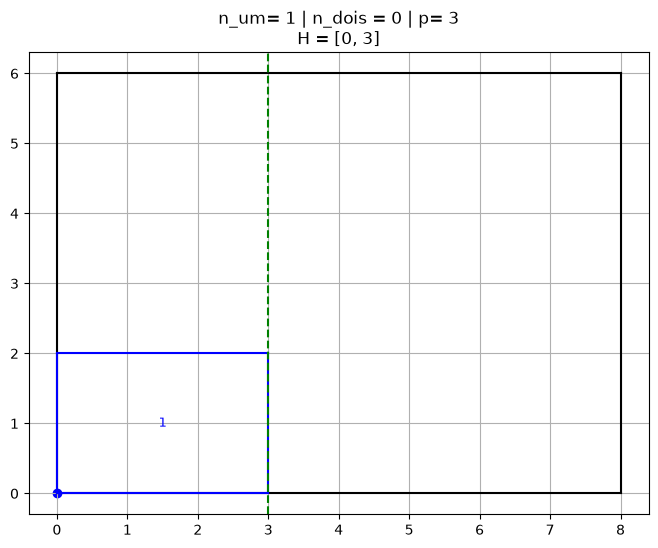

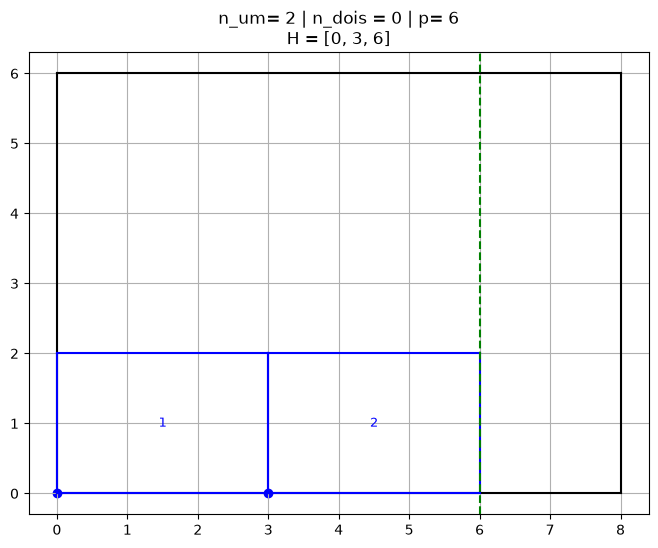

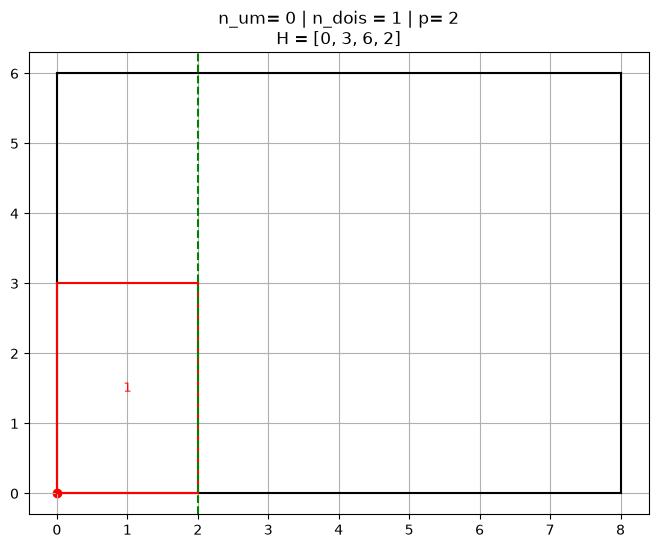

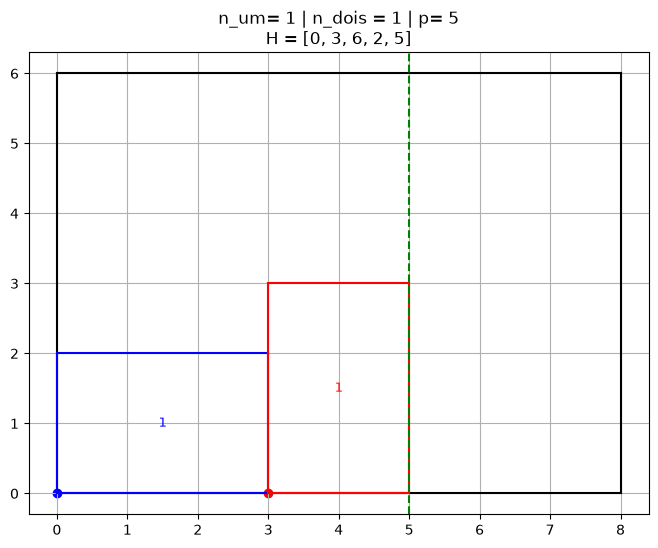

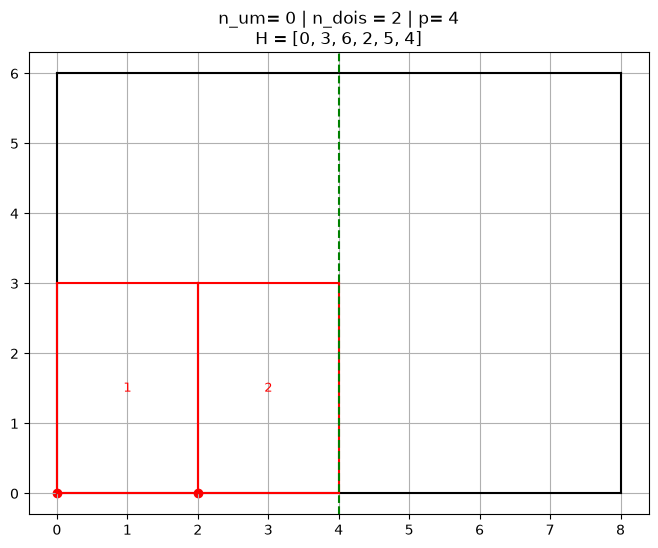

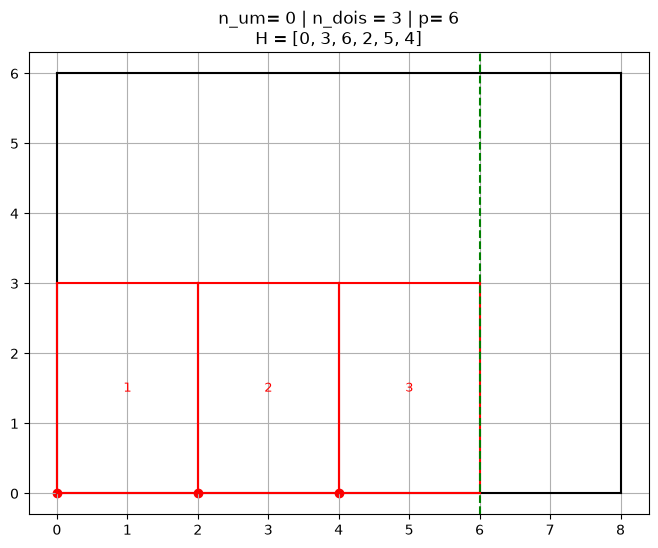

In [32]:
H = []
for n_dois, n_um in product(range(L), range(L)):
    # print (n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    print(n_um, n_dois, p)
    if p <= L - w_um:
        if p not in H:
            H.append(p)
        plotar_palete (L, W)
        for n in range(n_um):
            plotar_caixa(bottom_left=[n * l_um, 0], l=l_um, w=w_um, color="blue", label=n+1)
        for n in range(n_dois):
            plotar_caixa(bottom_left=[n_um * l_um + n *l_dois,0], l=l_dois, w=w_dois, color="red", label=n+1)

        plt.axvline(x=p, color="green", linestyle="--")
        plt.title(f"{n_um= } | {n_dois = } | {p= }\n{H = }")
        plt.grid()

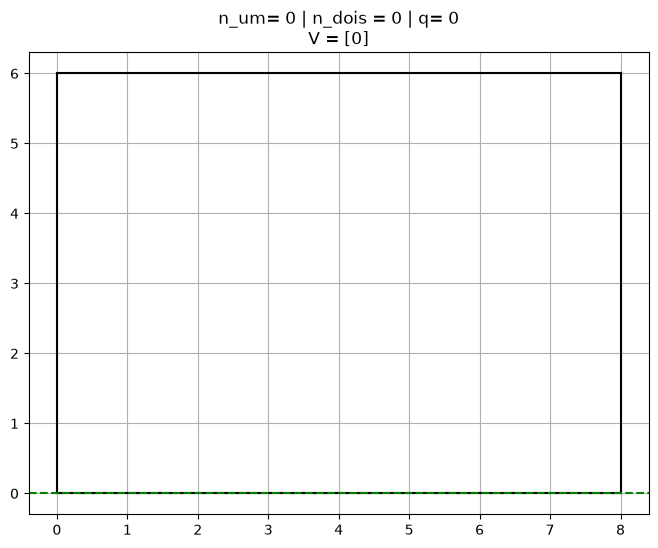

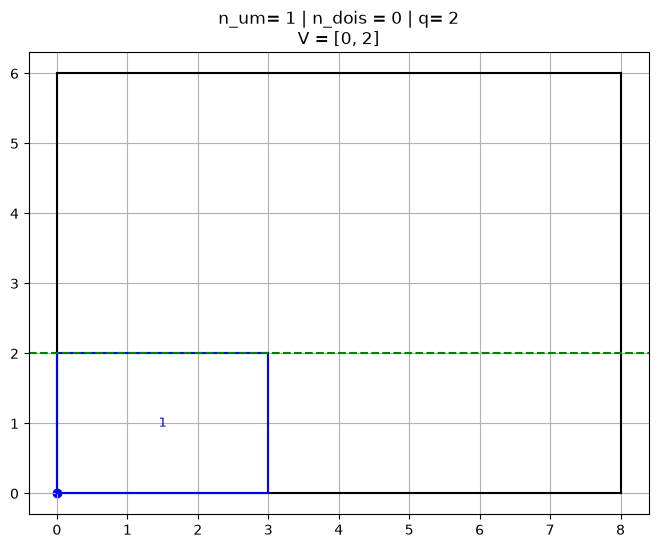

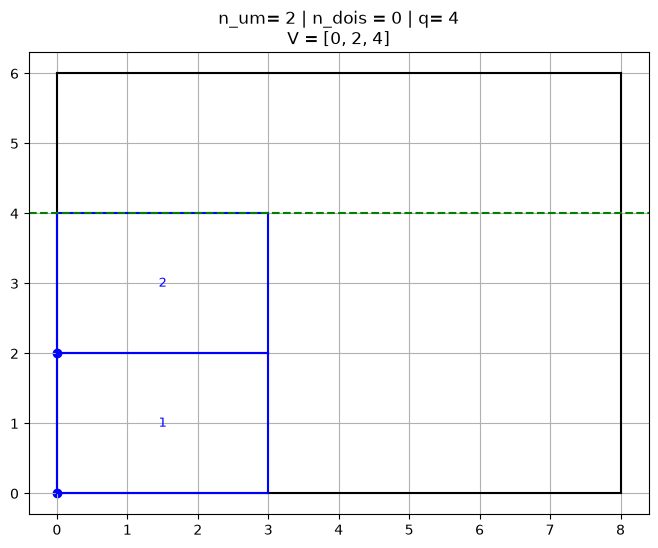

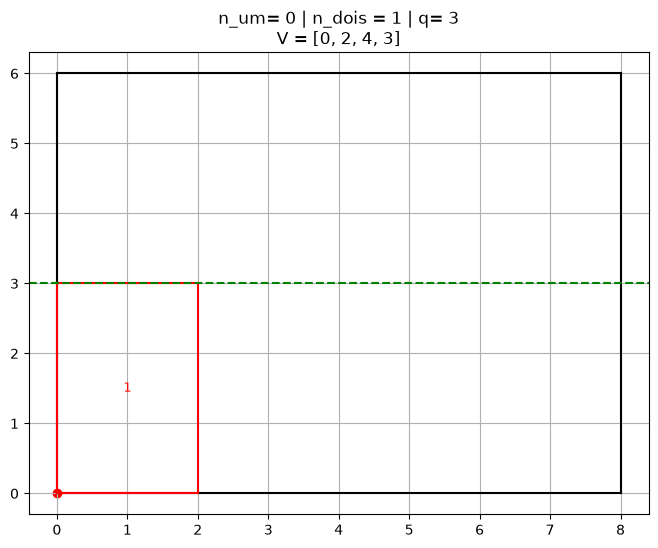

In [33]:
V = []
for n_dois, n_um in product(range(L), range(L)):
    # print (n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    # print(n_um, n_dois, q)
    if q <= W - w_um:
        if q not in V:
            V.append(q)
        plotar_palete (L, W)
        for n in range(n_um):
            plotar_caixa(bottom_left=[0, n * w_um], l=l_um, w=w_um, color="blue", label=n+1)
        for n in range(n_dois):
            plotar_caixa(bottom_left=[0, n_um * w_um + n *l_dois], l=l_dois, w=w_dois, color="red", label=n+1)

        plt.axhline(y=q, color="green", linestyle="--")
        plt.title(f"{n_um= } | {n_dois = } | {q= }\n{V = }")
        plt.grid()

In [34]:
H = sorted(H)
V = sorted(V)
print(H)
print(V)


[0, 2, 3, 4, 5, 6]
[0, 2, 3, 4]


In [35]:
lista_rs =list(product(H,V))
display(lista_rs)

[(0, 0),
 (0, 2),
 (0, 3),
 (0, 4),
 (2, 0),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, 0),
 (3, 2),
 (3, 3),
 (3, 4),
 (4, 0),
 (4, 2),
 (4, 3),
 (4, 4),
 (5, 0),
 (5, 2),
 (5, 3),
 (5, 4),
 (6, 0),
 (6, 2),
 (6, 3),
 (6, 4)]

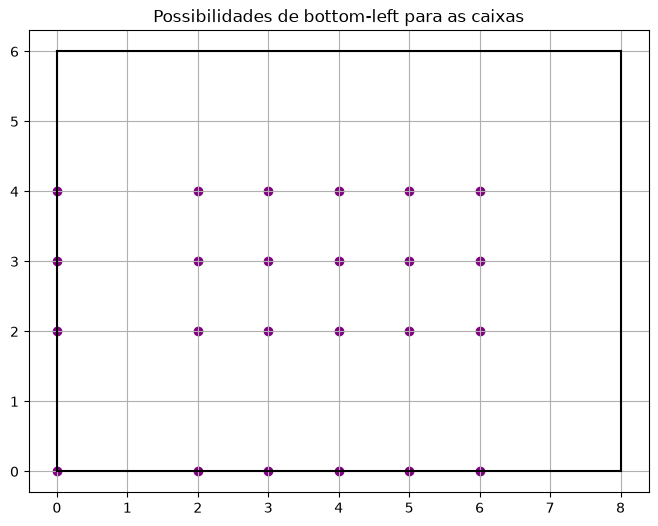

In [36]:
if indice == 0:
    plotar_palete (L, W)
    for r, s in lista_rs:
        plt.scatter(x=r, y=s, color ="purple")

    plt.title("Possibilidades de bottom-left para as caixas")
    plt.grid()
    plt.show()


In [37]:
ls = [l_um, l_dois]
ws = [w_um, w_dois]

In [38]:
i=1
print(ls[i-1], ws[i-1])

3 2


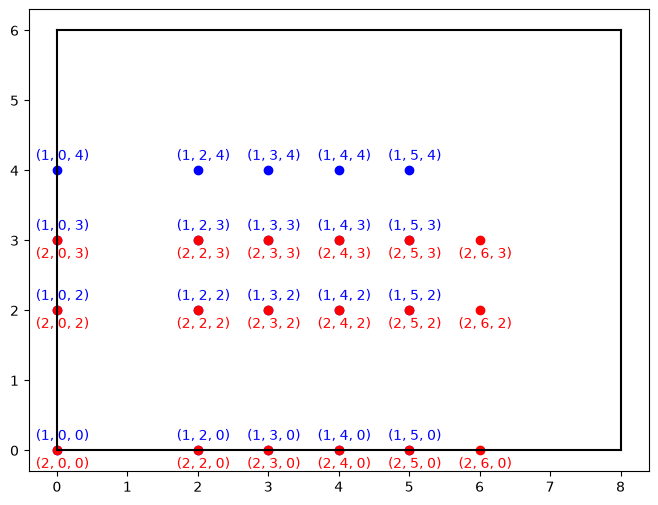

In [43]:
lista_variaveis=[]
plotar_palete (L, W)
for (p, q), i in product (lista_rs, [1, 2]):
    # print (i, p, q)
    # i=1 (caixa deitada)
    # i=2 (caixa em pé)
    if p + ls[i-1] <= L and q + ws[i-1] <= W: #checa se cabe no palete
        lista_variaveis.append ((i, p, q))

        if indice == 0:
            cor = "blue" if i == 1 else "red"
            plt.scatter (x =p, y = q, color = cor) #plota o bottom-left

            if i == 1:
                plt.text(x = p - 0.3, y = q + 0.15, s=f"({i}, {p}, {q})", color = cor, fontsize=10)
            else:
                plt.text (x = p - 0.3, y = q - 0.25, s=f"({i}, {p}, {q})", color=cor, fontsize=10)